# Defect Prediction with Machine Learning & SPC Feature Engineering
In this final notebook, we train supervised Machine Learning models on Phase I (`Train`, 800 batches) to predict which production batches in Phase II (`Test`, 767 batches) will fail quality inspection (`Defect == 1`). To connect our statistical process control framework with predictive modelling, we combine the Top 25 critical sensors from Phase I with three summary SPC engineered features: $\ln(1 + T^2_i)$, $\ln(1 + Q_i)$, and the maximum standardized sensor peak $\max_m |Z_{i,m}|$.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, recall_score, precision_score, f1_score, confusion_matrix

## 1. Loading the Cleaned Dataset & Phase I / Phase II Split
We load `data/secom_cleaned.csv` and use Phase I (batches 1–800, 9.0% defect rate) as our training set and Phase II (batches 801–1,567, 4.17% defect rate) as our chronological test set.

In [3]:
df = pd.read_csv('../data/secom_cleaned.csv')
sensor_cols = [s for s in df.columns if s.startswith('Sensor_')]
df_p1 = df[df['Phase'] == 'Phase I'].copy().reset_index(drop=True)
df_p1_ic = df_p1[df_p1['Defect'] == 0].copy().reset_index(drop=True)
df_p2 = df[df['Phase'] == 'Phase II'].copy().reset_index(drop=True)

y_train = df_p1['Defect'].values
y_test  = df_p2['Defect'].values

## 2. SPC Feature Engineering: Hotelling's $T^2$, $Q$ Statistic & Maximum Shewhart Peak
Using the baseline standardization and PCA model ($k = 87$ components) fitted strictly on the Phase I `In-Control` batches, we compute three statistical process control features for every batch in Phase I and Phase II:
1. **Hotelling's $T^2$:** Overall distance from the normal operating center inside the PCA subspace.
2. **Statistic $Q$ (SPE):** Squared reconstruction error outside the PCA subspace (correlation breakdown).
3. **Maximum Shewhart $|Z|$ Peak:** Largest individual standardized deviation across all 314 sensors.

In [4]:
# We redo things from Section 3: T^2 and Q
# Standarization
scaler = StandardScaler()
X_p1_ic_scaled = scaler.fit_transform(df_p1_ic[sensor_cols])
X_p1_scaled = scaler.transform(df_p1[sensor_cols])
X_p2_scaled = scaler.transform(df_p2[sensor_cols])

# We take k=87 principal components
k = 87
pca = PCA(n_components=k)
pca.fit_transform(X_p1_ic_scaled)
eigenvalues = pca.explained_variance_

T_p1 = pca.transform(X_p1_scaled)
T_p2 = pca.transform(X_p2_scaled)
# Hotelling's T^2
T2_p1 = np.sum((T_p1 ** 2) / eigenvalues, axis=1)
T2_p2 = np.sum((T_p2 ** 2) / eigenvalues, axis=1)
# Statistic Q
Q_p1 = np.sum((X_p1_scaled - pca.inverse_transform(T_p1)) ** 2, axis=1)
Q_p2 = np.sum((X_p2_scaled - pca.inverse_transform(T_p2)) ** 2, axis=1)
# Maxime individual peak: maxime Shewhart z-score of each batch
max_z_p1 = np.max(np.abs(X_p1_scaled), axis=1)
max_z_p2 = np.max(np.abs(X_p2_scaled), axis=1)

## 3. Feature Selection & Log-Transformation
Because we have 314 sensors and only 72 defective batches in Phase I, feeding all 314 raw channels directly into a classifier would cause severe overfitting. Instead, we select the **Top 25 sensors** most correlated with defects in Phase I and append our 3 SPC summary variables (`T2_log`, `Q_log`, and `Max_z`). We apply $\ln(1 + x)$ (`np.log1p`) to $T^2$ and $Q$ to compress extreme right-skewed spikes.

In [5]:
# Top 25 sensors most correlated with the variable 'Defect'
p1_corrs = df_p1[sensor_cols].apply(lambda x: abs(x.corr(df_p1['Defect']))).sort_values(ascending=False)
top25_sensors = p1_corrs.head(25).index.tolist()
# We now build the final matrixes with 25 variables of top 25 sensors + the 3 variables made above
X_train_df = df_p1[top25_sensors].copy()
X_train_df['T2_log'] = np.log1p(T2_p1)
X_train_df['Q_log']  = np.log1p(Q_p1)
X_train_df['Max_z']  = max_z_p1

X_test_df = df_p2[top25_sensors].copy()
X_test_df['T2_log'] = np.log1p(T2_p2)
X_test_df['Q_log']  = np.log1p(Q_p2)
X_test_df['Max_z']  = max_z_p2

# We will scale the matrices:
feature_names = X_train_df.columns.tolist()
final_scales = StandardScaler()
X_train = final_scales.fit_transform(X_train_df)
X_test  = final_scales.fit_transform(X_test_df)

## 4. Training & Evaluating Machine Learning Classifiers
We compare three classification algorithms trained on Phase I and evaluated on Phase II:
- **Logistic Regression (Balanced, $C = 0.1$):** Linear model with strong L2 regularization and balanced class weights.
- **Random Forest (Balanced, 300 trees, `max_depth=5`):** Bagging ensemble of shallow decision trees to prevent overfitting.
- **Gradient Boosting (100 trees, `max_depth=3`, `learning_rate=0.05`):** Sequential boosting ensemble.

Because defective batches represent only 4.17% of Phase II, we flag the top 25% highest-risk batches (`75th percentile` probability threshold) for quality inspection and evaluate ROC-AUC, Recall, Precision and F1-Score.

In [21]:
models = {
    'Logistic Regression': LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=5, 
                                            class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, 
                                                    learning_rate=0.05, random_state=42)
}

results_list = []
probs_dict = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    # Probabilities that the batch of Phase II is defected
    y_prob = model.predict_proba(X_test)[:,1]
    probs_dict[name] = y_prob

    # Threshold
    threshold = np.percentile(y_prob, 75)
    y_pred = (y_prob >=threshold).astype(int)

    auc = roc_auc_score(y_test, y_prob)
    recall = recall_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    cm = confusion_matrix(y_test, y_pred)
    results_list.append({
        'Model': name, 'ROC_AUC': round(auc,3), 'Recall': round(recall,3), 
        'Precision': round(prec,3), 'F1 Score': round(f1,3), 'con_matrix': cm})
results_df = pd.DataFrame(results_list).drop(columns='con_matrix')
with open('../reports/defect_prediction_metrics.md', 'w', encoding='utf-8') as f:
    f.write(results_df.to_markdown(index=False))
results_df

,Model,ROC_AUC,Recall,Precision,F1 Score
0,Logistic Regression,0.568,0.375,0.062,0.107
1,Random Forest,0.679,0.469,0.078,0.134
2,Gradient Boosting,0.610,0.438,0.073,0.125


### 4.1. Phase II Confusion Matrices
We visualize the Phase II confusion matrices across all three classifiers at the 75th percentile risk threshold to compare True Positives, False Positives, True Negatives, and False Negatives.

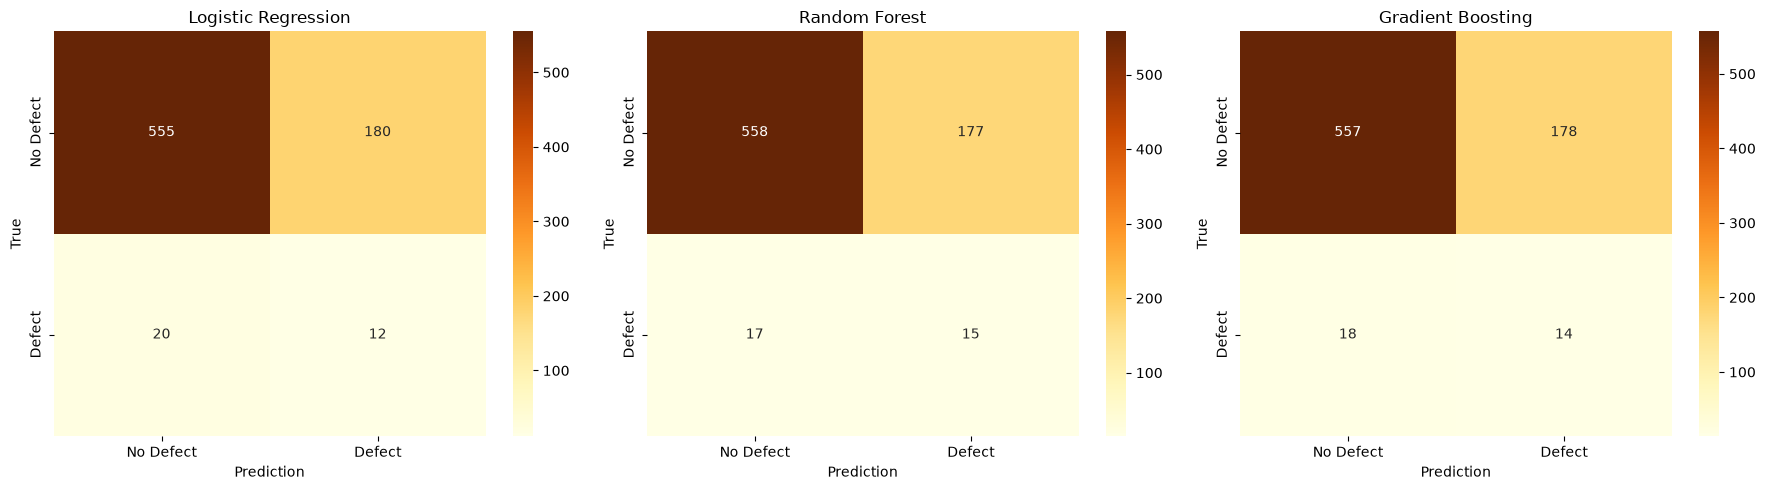

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, results in enumerate(results_list):
    model_name = results['Model']
    sns.heatmap(results['con_matrix'], annot = True, fmt='d', cmap='YlOrBr', ax=axes[i],
                xticklabels=['No Defect', 'Defect'], yticklabels=['No Defect', 'Defect'])
    axes[i].set_title(model_name)
    axes[i].set_xlabel('Prediction')
    axes[i].set_ylabel('True')
plt.tight_layout()
plt.savefig('../img/confusion_matrix.png', dpi=300)
plt.show()

## 5. Phase II ROC Curves & Top 10 Feature Importances
Finally, we plot the Phase II ROC curves for all three models alongside the Top 10 most important features from the Random Forest classifier to verify the predictive contribution of our engineered SPC statistics (`Q_log`, `Max_z`, and `T2_log`).

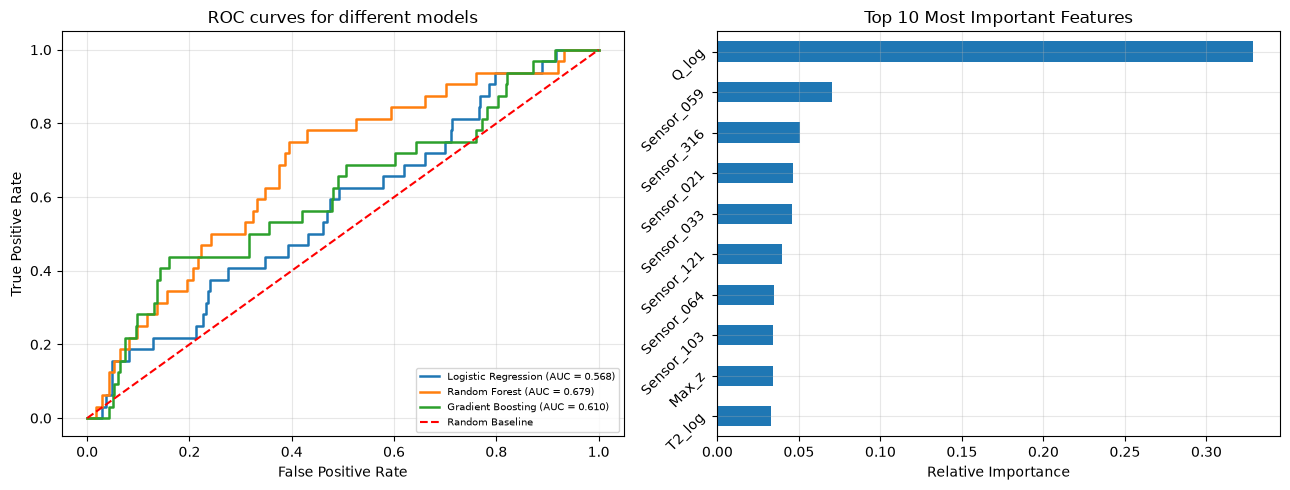

In [11]:
fig, axes = plt.subplots(1,2, figsize = (13,5))
# 1. ROC 
for name, y_prob in probs_dict.items():
    fpr, tpr, _ = roc_curve(y_test,y_prob)
    auc_val = roc_auc_score(y_test, y_prob)
    axes[0].plot(fpr, tpr, linewidth = 1.8, label = f'{name} (AUC = {auc_val:.3f})')
axes[0].plot([0,1],[0,1], color = 'red', linestyle = '--', label = 'Random Baseline')
axes[0].set_title('ROC curves for different models')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right', fontsize = 7)
axes[0].grid(alpha = 0.3)

# 2. Top 10 most important variables (in Random Forest)
rf_model = models['Random Forest']
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending = True).tail(10)
importances.plot(kind='barh', ax=axes[1])
axes[1].set_title('Top 10 Most Important Features')
axes[1].set_xlabel('Relative Importance')
axes[1].set_yticklabels(axes[1].get_yticklabels(),rotation=45)
axes[1].grid(alpha = 0.3)

plt.tight_layout()
plt.savefig('../img/defect_prediction_roc_importance.png', dpi=300)
plt.show()